# Representative episode timelines: Pro and Verified

Qwen3.5-9B · native AgentENV. Both campaigns use the original phase colors,
fonts, 12 episode lanes, and a **separate 9 × 5.5-inch figure per benchmark**.
SWE-bench Pro and SWE-bench Verified are displayed and exported independently.

Each concurrency panel (128/256/512 episode ceilings, or 16/32/64 groups of
8 episodes) selects four complete, error-free-call traces nearest its eligible
median lifetime. This conditional selection excludes errors and is not task-matched.
Pro's 512-episode point had an engine failure; the panels show surviving traces.
Verified's conditional 128-group / 1024-episode point was skipped.

Verified 256 uses the successful repetition **3674787**, with four newly selected
median-near episodes. Verified 128 and 512 retain their original runs. The original
failed 256 point and its episode selection remain in the frozen JSON metadata.


In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'uni_agent').is_dir() and (p / 'meta/plot').is_dir())
PLOT = REPO / 'meta/plot'
DATA = PLOT / 'data/episode_timelines_20261015.json'
FIGURES = PLOT / 'figure'
FIGURES.mkdir(parents=True, exist_ok=True)

sns.set_style('ticks')
sns.set_style({'font.family': ['Roboto', 'DejaVu Sans'], 'font.size': 12})
sns.set_context('paper', font_scale=2,
                rc={'lines.linewidth': 3, 'lines.markersize': 10})
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'pdf.fonttype': 42, 'ps.fonttype': 42,
    'svg.fonttype': 'none',
})
PALETTE = {
    'blue_main': '#0F4D92', 'blue_secondary': '#3775BA',
    'green_1': '#DDF3DE', 'green_2': '#AADCA9', 'green_3': '#8BCF8B',
    'red_1': '#F6CFCB', 'red_2': '#E9A6A1', 'red_strong': '#B64342',
    'neutral': '#CFCECE', 'highlight': '#FFD700',
    'teal': '#42949E', 'violet': '#9A4D8E',
}

In [2]:
SOURCES = [PLOT / 'data/episode_timelines_20261015.json',
           PLOT / 'data/episode_timelines_verified_20261016.json']
EXPECTED_SHA256 = ['5a7e589c61d3fa9d6715dcd94ff08c8d8b0cf308ebfc6d1302867f443eef05e5',
                   'cb1bd3fab716b6c77ff03a5cbfa59e74f59d2bfd353d976c43daf37acfa7d65f']
rows, startup_rows = [], []
for source, expected in zip(SOURCES, EXPECTED_SHA256):
    assert hashlib.sha256(source.read_bytes()).hexdigest() == expected
    data = json.loads(source.read_text())
    benchmark = data.get('benchmark', 'SWE-bench Pro V2')
    assert [p['episode_ceiling'] for p in data['points']] == [128, 256, 512]
    for point in data['points']:
        for index, episode in enumerate(point['episodes'], 1):
            rows.append({'benchmark': benchmark, 'campaign': point.get('campaign', data['campaign']),
                         'concurrent_trajectories': point['episode_ceiling'],
                         'lane': f'e{index}', 'sandbox_id': episode['sandbox_id'],
                         'trace_file': episode['trace_file'], 'lifetime_s': episode['lifetime_s'],
                         'model_calls': episode['model_calls'], 'eligible_episodes': point['eligible_episodes'],
                         **episode['phase_seconds']})
        startup_rows.append({'benchmark': benchmark, 'campaign': point.get('campaign', data['campaign']),
                         'concurrent_trajectories': point['episode_ceiling'],
                             'successful_starts': point['successful_start_calls'],
                             'median_cold_start_s': point['successful_start_median_s'],
                             'p90_cold_start_s': point['successful_start_p90_s']})
selection = pd.DataFrame(rows)
startup_summary = pd.DataFrame(startup_rows)
display(selection.round(2))
display(startup_summary.round(2))

,benchmark,campaign,concurrent_trajectories,lane,sandbox_id,trace_file,lifetime_s,model_calls,eligible_episodes,Cold Start,LLM Wait,Sandbox Interaction,Setup,Verification
0,SWE-bench Pro V2,sandbox-sweep-20261015_193213Z,128,e1,01a14144-2d84-7a03-9534-6d0f48fde025,2af832ab92cf46ce9d7e843bbaa998da.jsonl,84.13,6,759,2.28,4.59,2.81,0.92,73.53
1,SWE-bench Pro V2,sandbox-sweep-20261015_193213Z,128,e2,01a14142-fb0d-7ab3-8bbd-578f2cbd977e,4fbe39d2e542442b98922ac842aa4498.jsonl,84.19,4,759,2.56,3.04,1.97,0.91,75.70
2,SWE-bench Pro V2,sandbox-sweep-20261015_193213Z,128,e3,01a14140-87e9-75a0-992e-fdfe4c95bb27,8561f974481f4e7cbf623de6f072f278.jsonl,84.24,6,759,2.12,4.79,2.86,0.96,73.51
3,SWE-bench Pro V2,sandbox-sweep-20261015_193213Z,128,e4,01a14144-2d56-7aa2-aaff-2de80101ea86,3ab155384b5841feb64ed4368e02872a.jsonl,84.57,6,759,2.32,5.29,2.92,0.91,73.13
4,SWE-bench Pro V2,sandbox-sweep-20261015_193213Z,256,e1,01a1415d-028d-7b12-881e-35fe500c002a,dda076014e944bbc95a17902b73a3f93.jsonl,104.00,9,508,4.57,9.46,4.99,1.04,83.95
5,SWE-bench Pro V2,sandbox-sweep-20261015_193213Z,256,e2,01a1415e-00f4-7dd0-b595-4938dbd9f200,d8a62fc914394e908e9f61b3fa070cb8.jsonl,104.08,4,508,4.98,3.65,2.75,1.06,91.64
6,SWE-bench Pro V2,sandbox-sweep-20261015_193213Z,256,e3,01a14160-3aec-7310-a729-ffa036d38a73,cb756d56b8d4479b98a116ab0e5075a2.jsonl,104.32,8,508,4.68,14.60,4.10,1.07,79.87
7,SWE-bench Pro V2,sandbox-sweep-20261015_193213Z,256,e4,01a14157-069b-78f2-bcc6-8f590000460a,7df390dc64b74433a636a5358cd5d4f1.jsonl,104.53,8,508,11.27,36.65,7.18,0.91,48.52
8,SWE-bench Pro V2,sandbox-sweep-20261015_193213Z,512,e1,01a1416c-e458-7cb2-b507-26c86048701f,3457410b4ea94de2abfb9fdde0597a20.jsonl,140.55,4,173,15.73,18.01,1.84,0.87,104.11
9,SWE-bench Pro V2,sandbox-sweep-20261015_193213Z,512,e2,01a1416c-dc9a-7d83-b418-22b33fc313a2,00625fb1c2db4285815b6d3e3c7f3293.jsonl,146.84,4,173,18.05,19.90,1.93,0.86,106.10


,benchmark,campaign,concurrent_trajectories,successful_starts,median_cold_start_s,p90_cold_start_s
0,SWE-bench Pro V2,sandbox-sweep-20261015_193213Z,128,1021,2.68,3.91
1,SWE-bench Pro V2,sandbox-sweep-20261015_193213Z,256,1020,4.90,12.48
2,SWE-bench Pro V2,sandbox-sweep-20261015_193213Z,512,1024,11.47,25.65
3,SWE-bench Verified,verified_sweep_20261015_235315Z,128,1024,2.43,4.02
4,SWE-bench Verified,verified_rerun_c256_retry_20261016_100619Z,256,1024,3.60,7.02
5,SWE-bench Verified,verified_sweep_20261015_235315Z,512,1011,9.24,21.55


## Phase conventions

**LLM Wait**, **Cold Start**, **Setup**, **Sandbox Interaction**, and **Verification**
retain the reference palette and legend order. Cold Start includes native readiness;
Setup ends at the first model call. Sandbox Interaction consists of measured native
operations during the agent phase. Verification is inferred from final shell-close
to stop invocation, including patch/artifact overhead. LLM Wait is residual time,
including model calls and untraced overhead. Deletion duration is excluded.

Error-free API calls do not prove completed reward verification or task resolution.
Pro had the accidental 180-second verifier cap; Verified uses the corrected deadline
and warmed images. Different task sets, setup costs, and cache histories preclude a
controlled performance comparison between benchmarks.

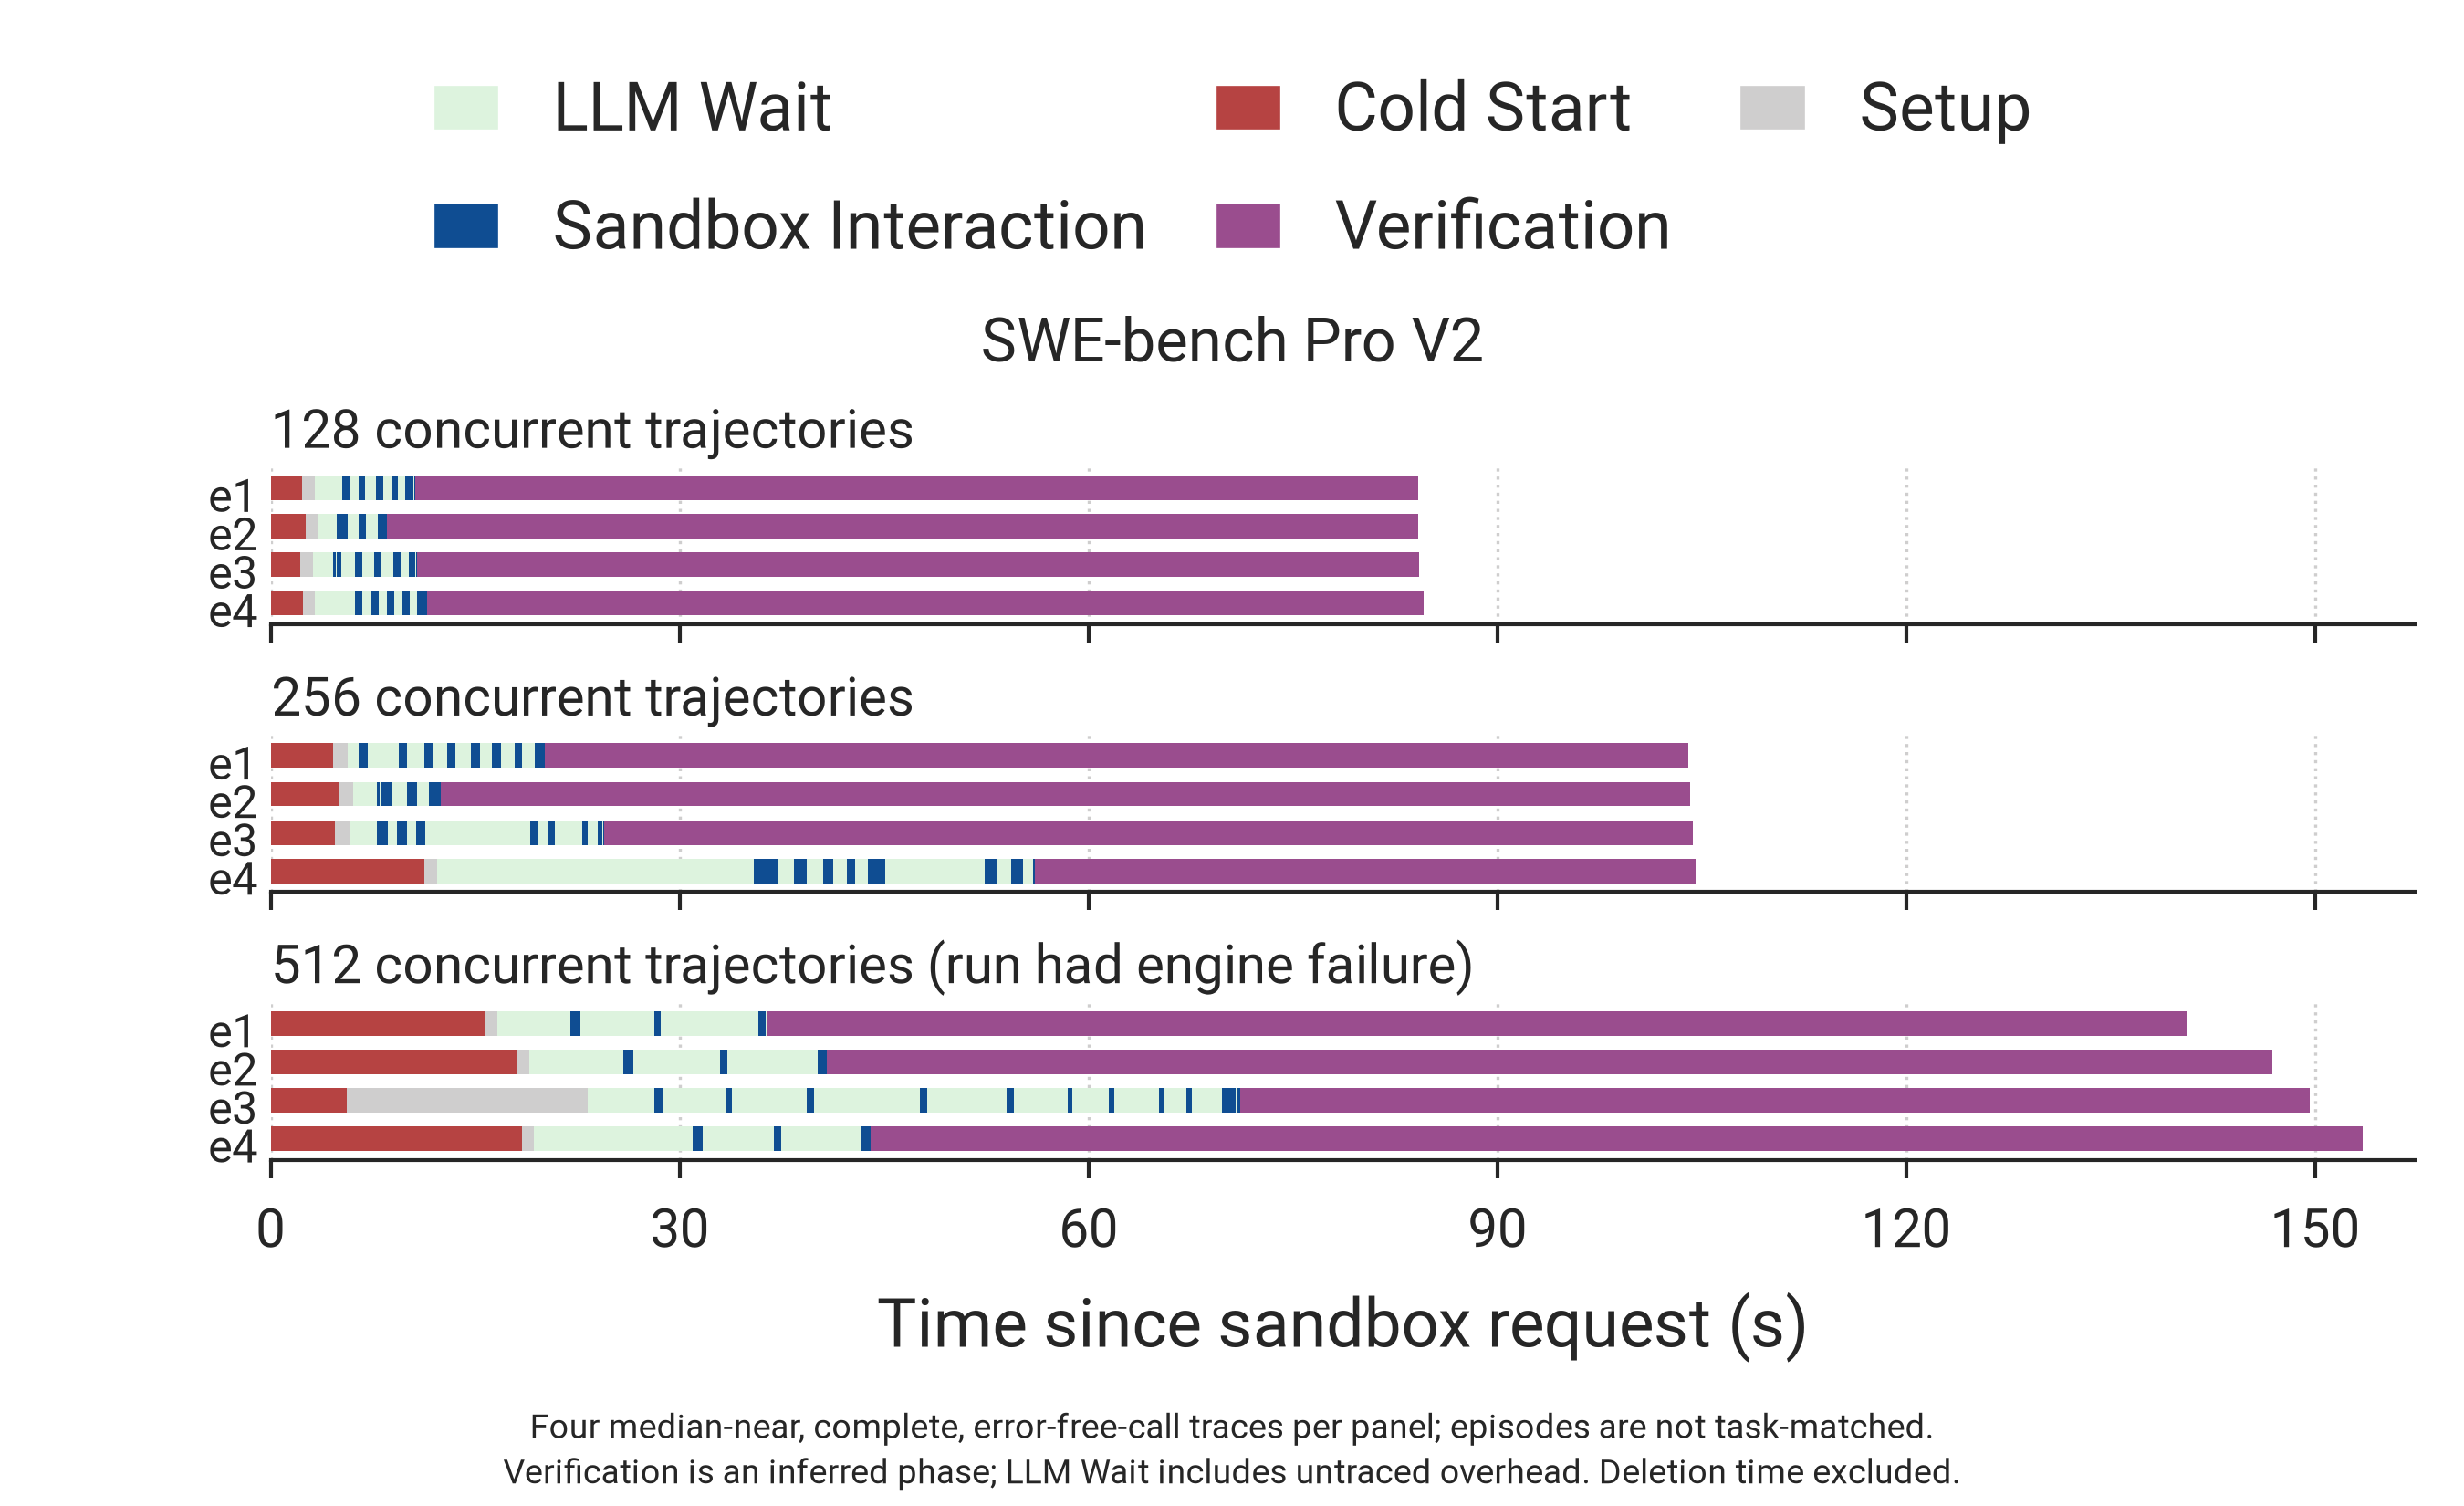

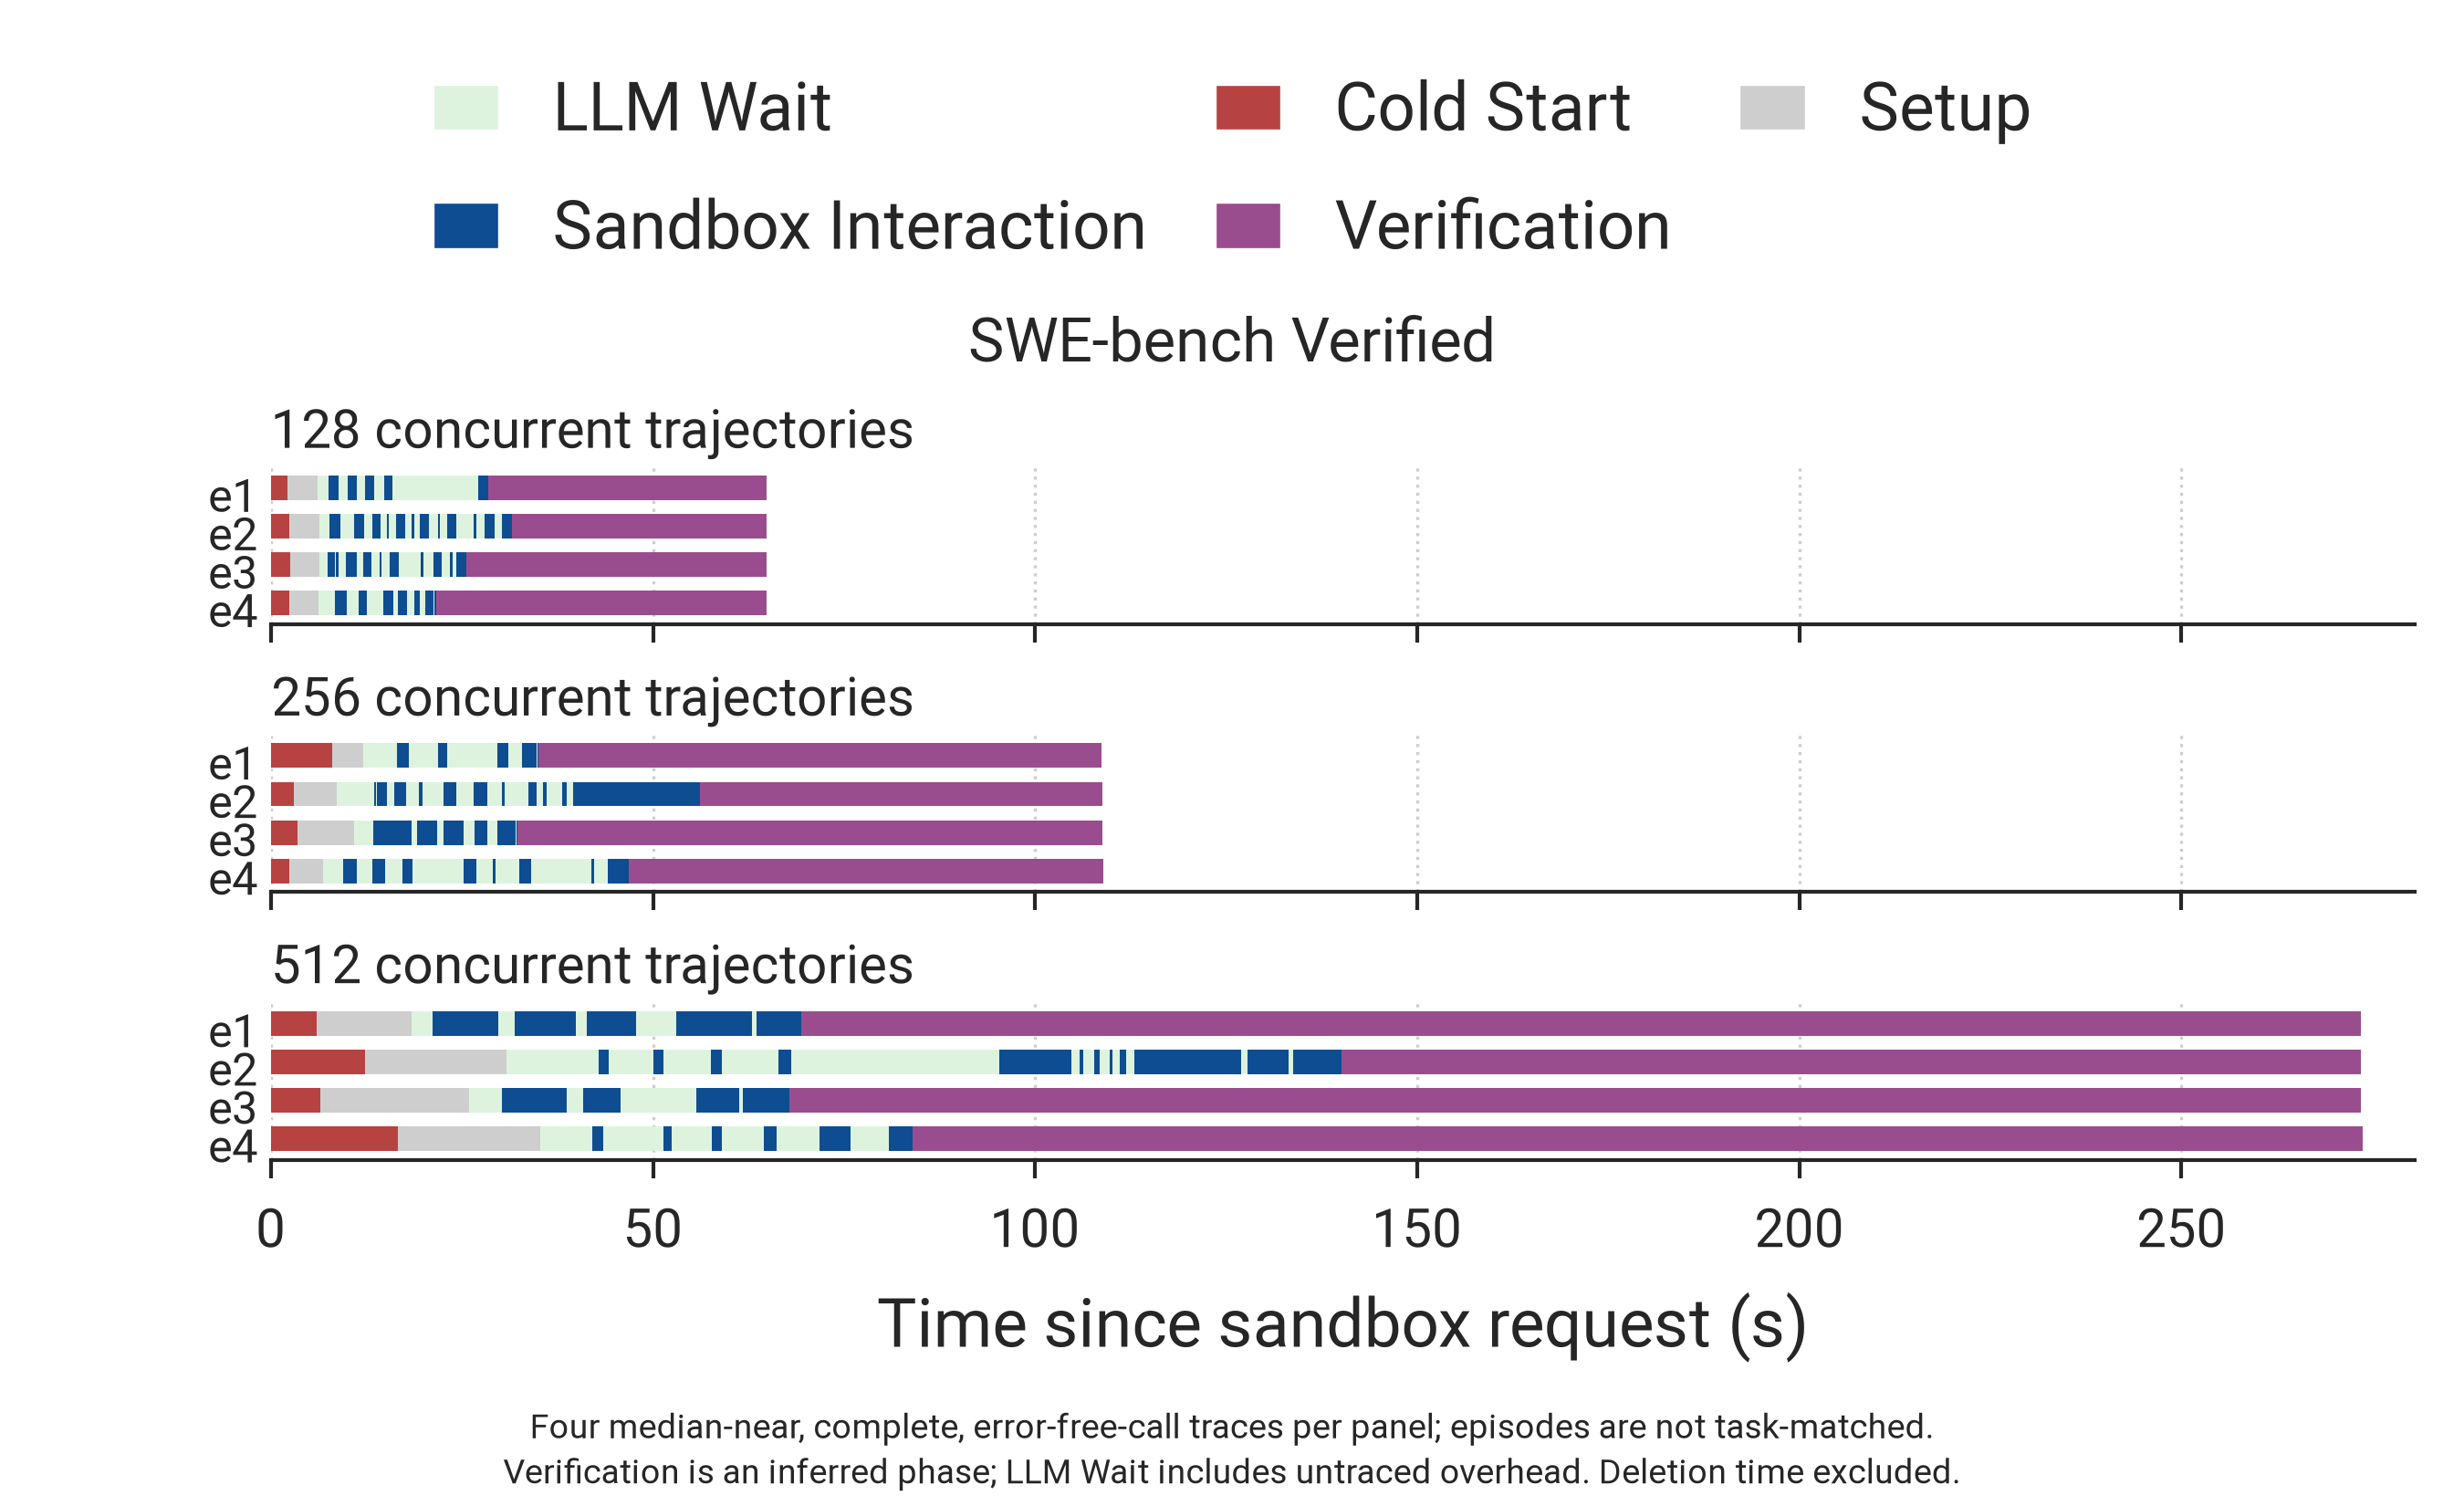

In [3]:
import runpy
from IPython.display import Image

# The notebook and command-line script share one renderer and styling definition.
render = runpy.run_path(str(PLOT / 'plot_episode_timelines.py'))['plot']
for source, suffix in zip(SOURCES, ('pro', 'verified')):
    render([source], FIGURES / f'episode_timelines_{suffix}')
    display(Image(filename=str(FIGURES / f'episode_timelines_{suffix}.png')))

The separate SVG/PDF/PNG exports are `figure/episode_timelines_pro.*`
and `figure/episode_timelines_verified.*`.
Selected sandbox IDs, source hashes, timing intervals, and eligibility counts
are stored in frozen JSON and the exported selection/startup CSVs. No remote
access or ignored `outputs/` files are required to run this notebook.